# Какие 20 рамок оператору проверить первыми?

Камера кафе уже находит людей и предметы. У оператора есть время проверить лишь часть записей. Мы меняем порядок просмотра: первыми идут рамки, в которых повторная проверка изображения обнаружила признаки ошибки.

**Результат на двух размеченных днях.** Если открыть первые 20 рамок каждого дня, обычная очередь по уверенности покажет 32 ошибки за 40 проверок. Обе финальные версии показывают 39. Это семь дополнительных находок при том же числе открытых записей.

Таблицы и график ниже сохранены для чтения на GitHub. Для пересчёта откройте ноутбук из корня репозитория, укажите папку конкурса в первой ячейке и выполните **Run All**. Достаточно CPU и пяти файлов данных из [README](README.md).

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
DATA = ROOT / "data" / "rascar-hack-case-1"  # Здесь можно указать свою папку датасета.
sys.path.insert(0, str(ROOT / "finalist"))
import reproduce as solution

solution.r.DATA = DATA
solution.r.WORK = ROOT / "outputs" / "redetect_strong"
train = solution.predictions("train")
train["uncertainty"] = 1 - train["confidence"]
methods = {
    "uncertainty": "По уверенности",
    solution.LEADER: "Базовая проверка",
    solution.POSE: "Усиленная проверка людей",
}

## Почему порядок стоит менять

Ниже две реальные рамки кистей с одинаковой уверенностью детектора. Разметчик подтвердил первую рамку. У второй границы оказались недостаточно точными. Мы повторно ищем объект на изображении. Если большинство прогонов не нашли кисть примерно в том же месте, исходная запись поднимается в очереди. Ручной ответ нужен, чтобы проверить этот вывод после расчёта.

In [2]:
columns = {
    "confidence": "Уверенность",
    "votes": "Прогонов без пары из 6",
    solution.LEADER: "Приоритет проверки",
    "error": "Ошибка по разметке",
}
example_ids = ["4304e712abf33257", "0942ed971fd2436b"]
examples = train.set_index("id").loc[example_ids, list(columns)].rename(columns=columns)
display(examples.round(3))

,Уверенность,Прогонов без пары из 6,Приоритет проверки,Ошибка по разметке
id,,,,
4304e712abf33257,0.83,1.0,0.084,0
0942ed971fd2436b,0.83,6.0,0.292,1


## Что увидит оператор за одинаковое число проверок

Сравним три очереди на одних и тех же записях. Для проверки 25 октября детекторы обучались на 26 октября, для проверки 26-го — на 25-м. Выбираем первые K рамок отдельно в каждом дне. Если на границе несколько рамок с одинаковым приоритетом, считаем ожидаемое число находок при случайном порядке среди них. Поле K можно менять для другого бюджета просмотра.

,По уверенности,Базовая проверка,Усиленная проверка людей
Отложенный день,,,
25.10,17.0,19.0,19.0
26.10,15.0,20.0,20.0


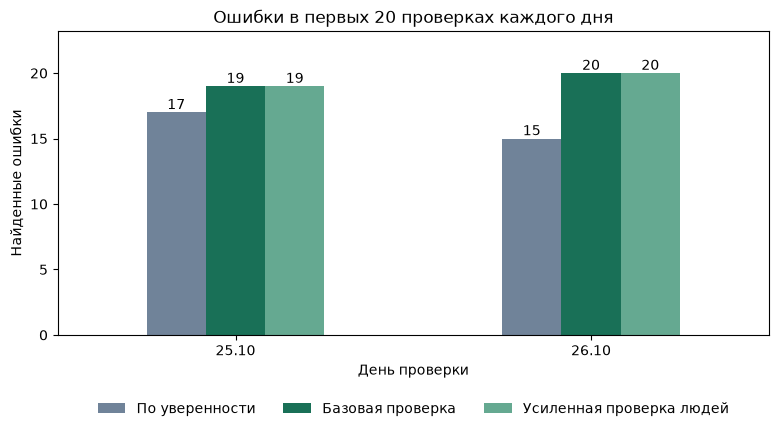

In [3]:
K = 20

def errors_in_first_k(day, score, k):
    if not 1 <= k <= len(day):
        raise ValueError(f"K должно быть от 1 до {len(day)} для этого дня")
    cutoff = day[score].nlargest(k).min()
    ahead = day[score] > cutoff
    tied = day[score] == cutoff
    return day.loc[ahead, "error"].sum() + (k - ahead.sum()) * day.loc[tied, "error"].mean()

counts = pd.DataFrame({
    title: {pd.to_datetime(date).strftime("%d.%m"): errors_in_first_k(day, score, K)
            for date, day in train.groupby("day")}
    for score, title in methods.items()
})
display(counts.rename_axis("Отложенный день"))
ax = counts.plot.bar(rot=0, color=["#708399", "#197057", "#65a991"], figsize=(8, 4.5))
ax.set(title=f"Ошибки в первых {K} проверках каждого дня", xlabel="День проверки",
       ylabel="Найденные ошибки", ylim=(0, K * 1.16))
for bars in ax.containers:
    ax.bar_label(bars, fmt="%g")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

**Как читать результат при K = 20.** 25 октября оператор увидел бы 19 ошибочных рамок вместо 17; 26 октября — 20 вместо 15. В пересчёте на 40 проверок число открытых правильных рамок снизилось с восьми до одной. Эти два дня показывают, как система расходует внимание оператора. Реальное время просмотра каждой записи ещё предстоит измерить.

## Почему в финале два варианта

Вторая версия увеличивает влияние модели позы, когда проверяем человека в зале. По первым двадцати находкам варианты сравнялись, но AP учитывает порядок во всём списке. На отложенных днях усиленный вариант получил 0.93343 и 0.93435, базовый — 0.92579 и 0.92565. На конкурсной выборке Kaggle Public выше базовый вариант — 0.92465 против 0.92144. Ниже проверим, что код воспроизводит обе отправки.

In [4]:
test = solution.predictions("test").set_index("id")
for filename in (solution.LEADER, solution.POSE):
    submitted = pd.read_csv(ROOT / "submissions" / filename, dtype={"id": str}).set_index("id")
    assert test.index.is_unique and submitted.index.is_unique
    assert len(submitted) == 362 and set(test.index) == set(submitted.index)
    rebuilt = test.loc[submitted.index, filename]
    np.testing.assert_allclose(rebuilt, submitted.score, rtol=0, atol=1e-12)
    print(f"{methods[filename]}: совпали все {len(rebuilt)} оценок")

Базовая проверка: совпали все 362 оценок
Усиленная проверка людей: совпали все 362 оценок


## Решение о пилоте

Сервис можно поставить после действующего детектора: на входе остаются его рамки, на выходе оператор получает ту же работу в другом порядке. Пропуски самого детектора в очередь не попадают. Данные пока относятся к одной камере и двум размеченным дням; зона окна и видимость ног меняются вместе с ракурсом.

**Следующий шаг** — зафиксировать настройки и сравнить обе очереди на новых сменах и второй камере. Основной показатель пилота — подтверждённые ошибки за час работы оператора. Одновременно измерим длительность обработки кадра на оборудовании заказчика и стоимость тысячи кадров. Это даст основания выбирать между полной и облегчённой конфигурациями. [Метод и источники весов](REPORT.md) · [Повторное обучение](TRAINING.md)